## Importação e Início

In [1]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
plt.style.use('ggplot')

In [2]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
gdown.download(url=url, output=output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=10izoanxrZJnQzkV9UpPI-DX9bt2mYG62
To: c:\UFRN\Matérias\02 Período\Ciencia de dados\datascienceproject\filmes.json
100%|██████████| 31.8M/31.8M [00:03<00:00, 9.64MB/s]


'filmes.json'

In [7]:
df = pd.read_json('filmes.json', orient='records')

## Primeira Análise

In [10]:
df.head()

,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,profit,roi
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.247,29099,2582567784,7.2544
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.611,34904,2686706026,11.3363
2,False,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg,"{'id': 531241, 'name': 'Spider-Man (MCU) Colle...",225000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://spidermanbrandnewday.movie,969681,tt22084616,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,A brand new day starts now.,Spider-Man: Brand New Day,False,8.468,6037,2291291000,10.1835
3,False,/kJsPVzdyBrYHLomuNv5SJDXUQ2f.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",460000000,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",https://www.avatar.com/movies/avatar-the-way-o...,76600,tt1630029,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Return to Pandora.,Avatar: The Way of Water,False,7.581,14813,1874484620,4.0750
4,False,/gd9kxeEEONj5SECs4GA8Ddn3czI.jpg,"{'id': 1449595, 'name': 'Ne Zha Collection', '...",80000000,"[{'id': 16, 'name': 'Animation'}, {'id': 28, '...",https://a24films.com/films/ne-zha-2,980477,tt34956443,[CN],zh,...,False,"[{'english_name': 'Mandarin', 'iso_639_1': 'zh...",Released,Witness a hero reborn.,Ne Zha 2,False,8.204,856,2190700370,27.3838


In [42]:
df.info()
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 16541 entries, 0 to 16540
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  16541 non-null  bool   
 1   backdrop_path          14475 non-null  str    
 2   belongs_to_collection  2812 non-null   object 
 3   budget                 16541 non-null  int64  
 4   genres                 16541 non-null  object 
 5   homepage               16541 non-null  str    
 6   id                     16541 non-null  int64  
 7   imdb_id                14108 non-null  str    
 8   origin_country         16541 non-null  object 
 9   original_language      16541 non-null  str    
 10  original_title         16541 non-null  str    
 11  overview               16541 non-null  str    
 12  popularity             16541 non-null  float64
 13  poster_path            16190 non-null  str    
 14  production_companies   16541 non-null  object 
 15  production_co

Index(['adult', 'backdrop_path', 'belongs_to_collection', 'budget', 'genres',
       'homepage', 'id', 'imdb_id', 'origin_country', 'original_language',
       'original_title', 'overview', 'popularity', 'poster_path',
       'production_companies', 'production_countries', 'release_date',
       'revenue', 'runtime', 'softcore', 'spoken_languages', 'status',
       'tagline', 'title', 'video', 'vote_average', 'vote_count', 'profit',
       'roi', 'collection'],
      dtype='str')

### Retirada de Colunas Inúteis

In [6]:
df.drop(columns=['backdrop_path','homepage', 'poster_path','popularity','status','adult','tagline'], inplace=True)

### Retirada de Outliers

In [46]:
quantidade = (df['budget'] < 10).sum()
print(quantidade)

599


In [59]:
df = df[
    (df['roi'] <= 50000) &
    (df['budget'] > 1000) &
    (df['vote_count'] > 50)
].copy()

## Divisão por Filme

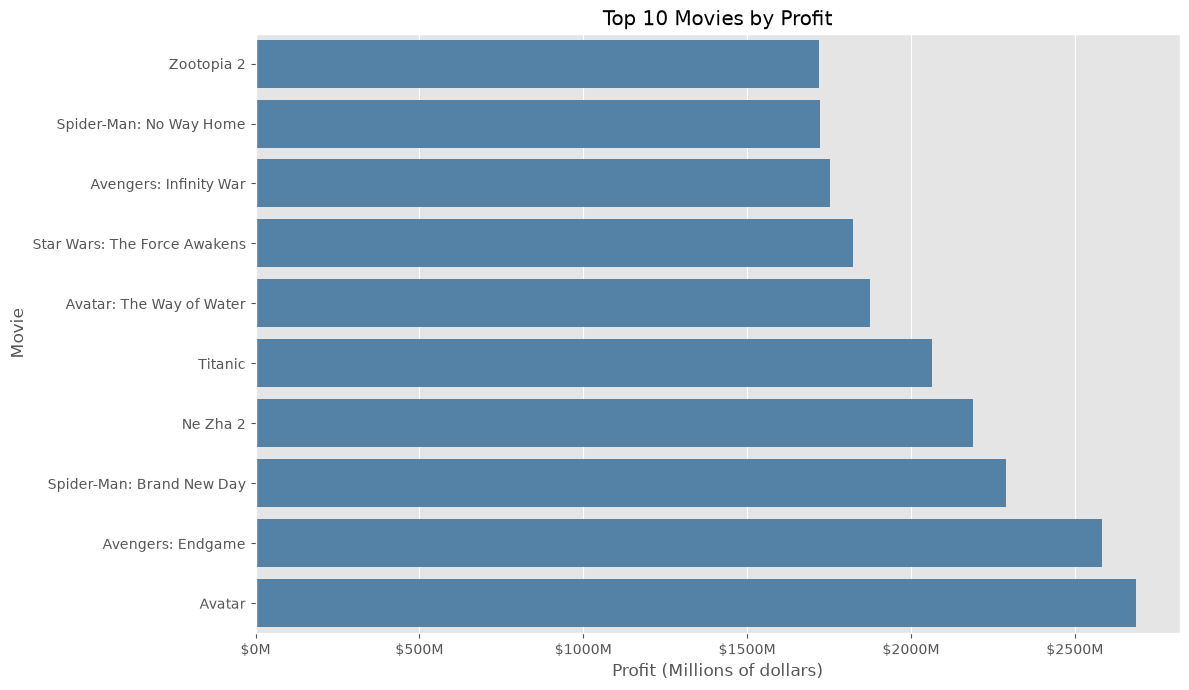

In [35]:
top_10_movies_profit = df.nlargest(10, 'profit').sort_values('profit')

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=top_10_movies_profit,
    x='profit',
    y='title',
    color='steelblue'
)

ax.set_title('Top 10 Movies by Profit')
ax.set_xlabel('Profit (Millions of dollars)')
ax.set_ylabel('Movie')

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value / 1_000_000:.0f}M')
)

plt.tight_layout()
plt.show()

## Divisão Por Gênero

In [36]:
df_genres = df.explode('genres').copy()
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)
df_genres.drop(columns='genres', inplace=True)

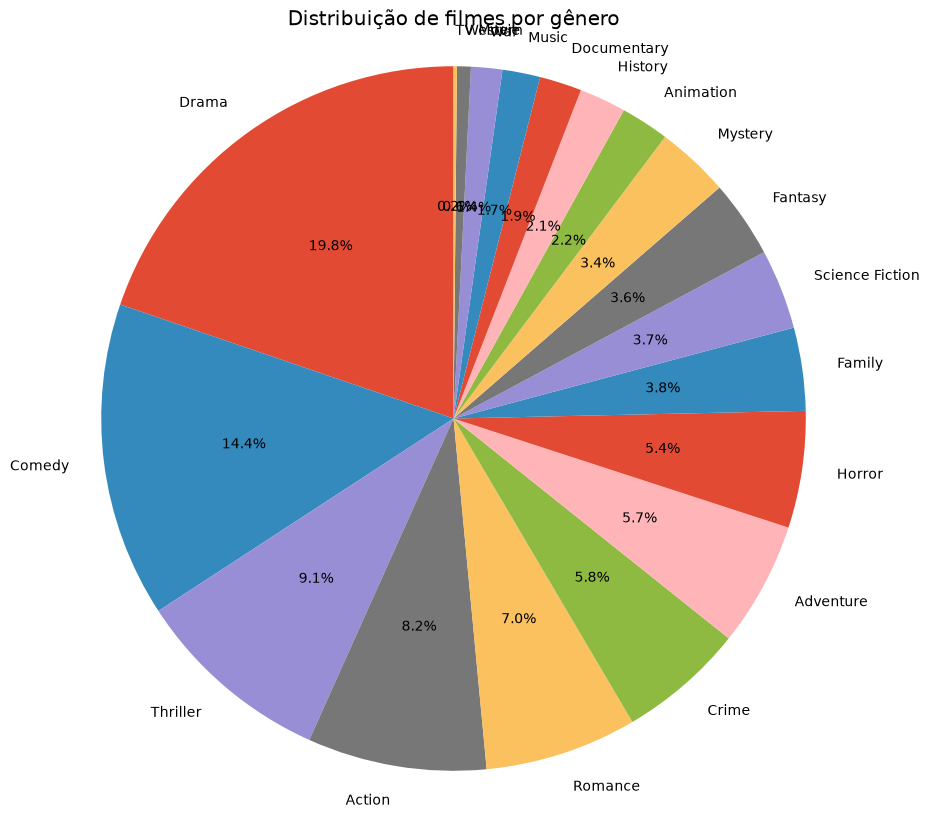

In [28]:
genre_counts = df_genres['genre'].dropna().value_counts()

plt.figure(figsize=(10, 10))
plt.pie(
    genre_counts,
    labels=genre_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribuição de filmes por gênero')
plt.axis('equal')
plt.show()

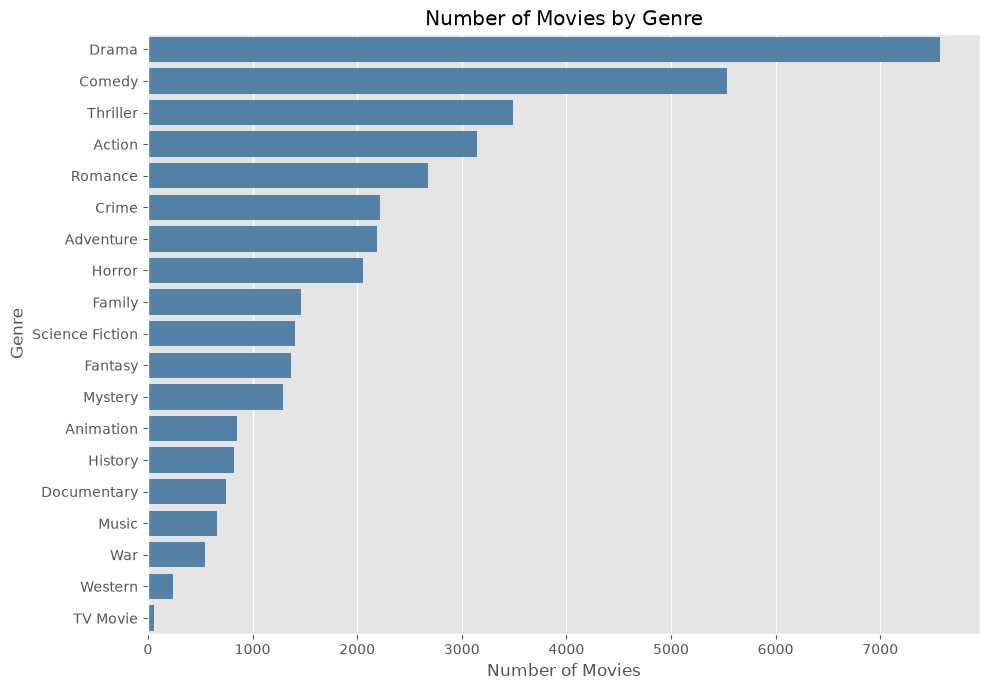

In [34]:
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    color='steelblue'
)

ax.set_title('Number of Movies by Genre')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Genre')

plt.tight_layout()
plt.show()

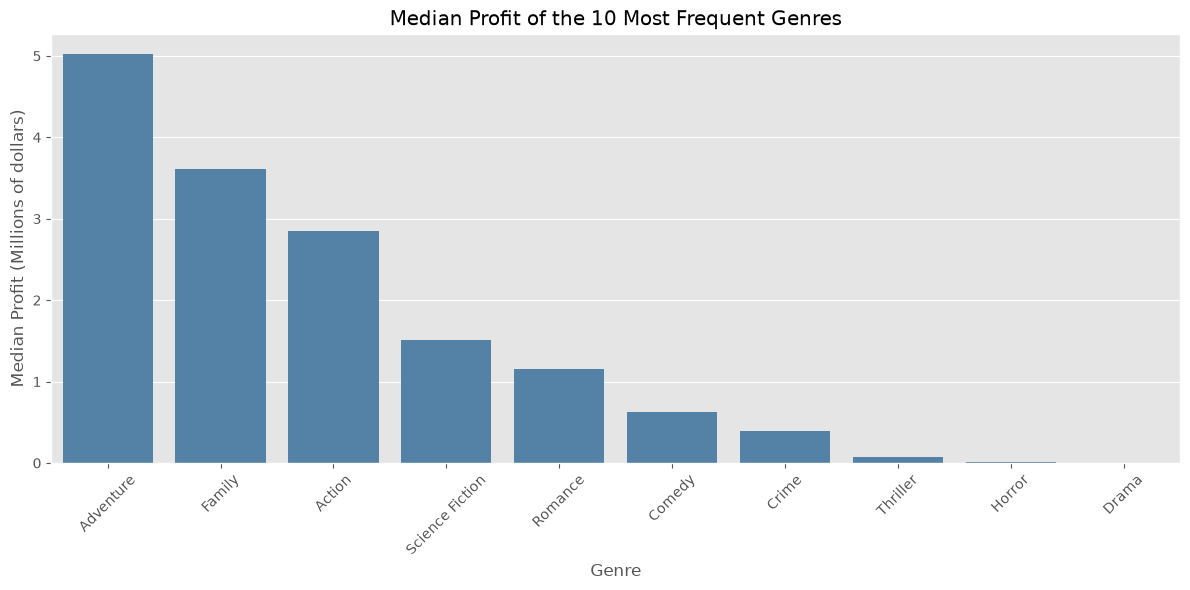

In [32]:
median_profit_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['profit']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_profit_by_genre.index,
    y=median_profit_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Profit of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Profit (Millions of dollars)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
median_budget_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['budget']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_budget_by_genre.index,
    y=median_budget_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Budget of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Budget (Millions of dollars)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Divisão Por Coleções

In [37]:
df['collection'] = df['belongs_to_collection'].apply(
    lambda collection: collection.get('name')
    if isinstance(collection, dict)
    else np.nan
)

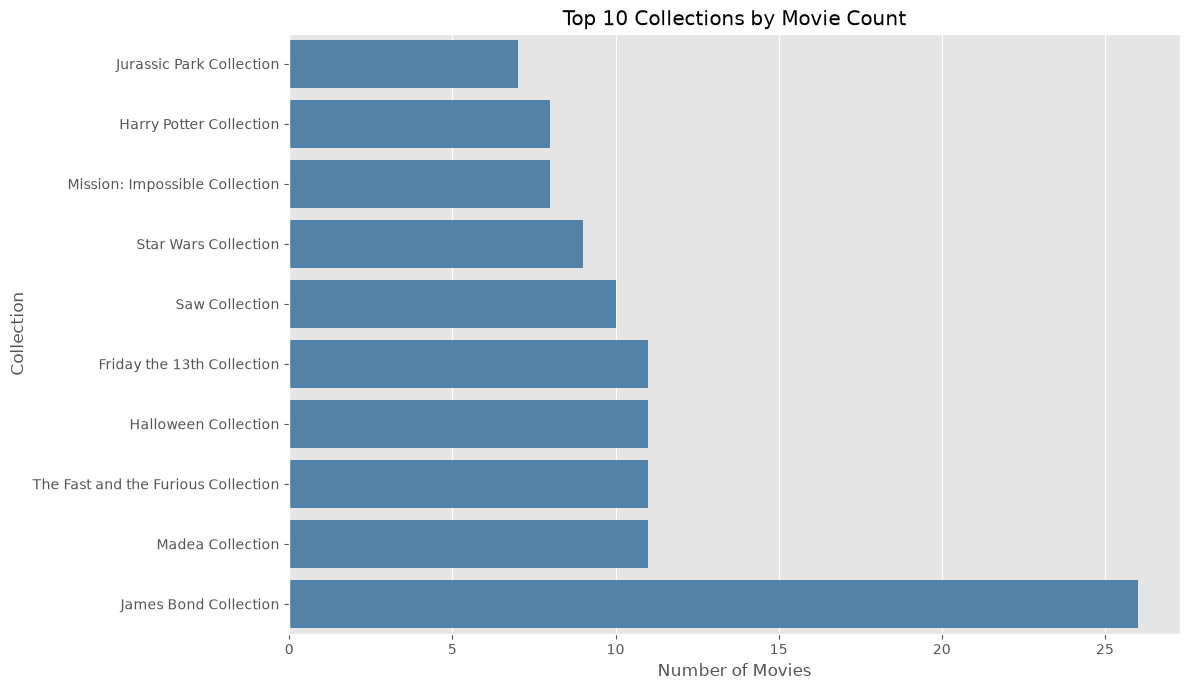

In [38]:
top_collections = (
    df['collection']
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    x=top_collections.values,
    y=top_collections.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Movie Count')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

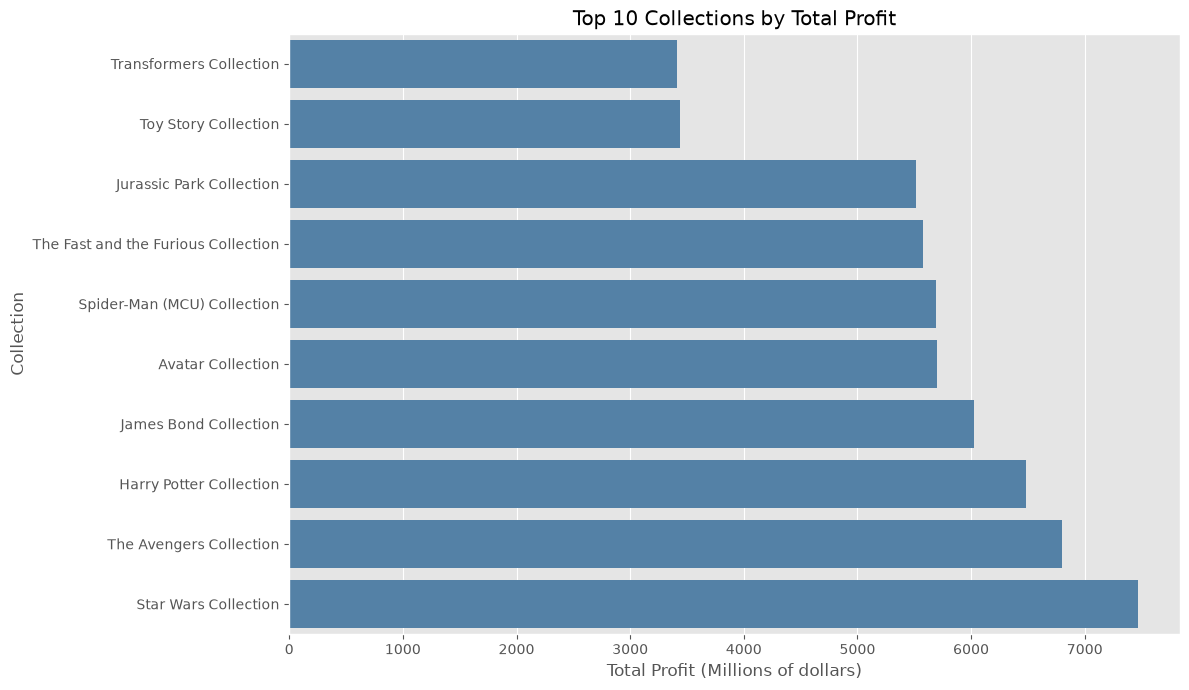

In [40]:
top_collections_by_profit = (
    df.dropna(subset=['collection'])
      .groupby('collection')['profit']
      .sum()
      .nlargest(10)
      .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_collections_by_profit.values / 1_000_000,
    y=top_collections_by_profit.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Total Profit')
ax.set_xlabel('Total Profit (Millions of dollars)')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

## Analise de ROI

In [61]:
top_roi_movies = (
    df
    .nlargest(10, 'roi')
    .sort_values('roi')
)

top_roi_movies[['title', 'roi', 'budget', 'revenue', 'vote_count']]


,title,roi,budget,revenue,vote_count
7644,Pink Flamingos,499.0000,12000,6000000,592
4380,One Cut of the Dead,525.4699,52406,27590180,1056
1417,Mr. Six,555.7654,250000,139191345,182
2539,Animal World,558.0856,125000,69885700,273
261,Obsession,696.6736,750000,523255189,6298
5143,The Brothers McMullen,772.0602,25000,19326506,107
1932,The Birth of a Nation,999.0000,100000,100000000,623
1933,Fist of Fury,999.0000,100000,100000000,1126
746,The Blair Witch Project,4142.9850,60000,248639099,5746
1002,Paranormal Activity,12889.3867,15000,193355800,5634
